# Most Used Lyrics in the Billboard Hot 100 (1946–2022)

**Question:** What words appear most often in Billboard Hot 100 hit songs, and how has that lyrical vocabulary changed across 8 decades?

**Dataset:** 6,032 Billboard Hot 100 songs (1946–2022), including lyrics, artist, year, and chart rank.

**Approach:**
1. Clean and tokenize lyrics
2. Remove stopwords/filler in stages to isolate meaningful content words
3. Measure word usage by **song coverage** (% of songs containing a word) rather than raw word count, so a single repetitive chorus can't skew results
4. Compare word usage across decades to find trends

**Key finding (spoiler):** "Love" was the single most dominant word in Billboard lyrics from the 1940s through the 1990s, peaking in 1990 at ~62% of songs. Since then, its dominance has declined as lyrical vocabulary has diversified — more casual, conversational words like "out," "baby," and "time" have risen to match it.

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import ast

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 1. Load & Clean Data

In [2]:
df = pd.read_csv('billboard_top_100_1946_2022_lyrics-edited.csv')

# Standardize column names
df = df.rename(columns={
    'Song': 'song',
    'Artist Names': 'artist',
    'Hot100 Ranking Year': 'year',
    'Hot100 Rank': 'rank',
    'Lyrics': 'lyrics'
})

# Add a decade column for grouping (e.g. 1987 -> 1980)
df['decade'] = (df['year'] // 10) * 10

df.head()

,song,artist,year,rank,lyrics,decade
0,Prisoner of Love - Remastered - 1992,['perry como'],1946,1,"['someone', 'that', 'i', 'belong', 'to', 'does...",1940
1,To Each His Own,['eddy howard'],1946,2,"['a', 'rose', 'must', 'remain', 'with', 'the',...",1940
2,The Gypsy,['the ink spots'],1946,3,"['in', 'a', 'quaint', 'caravan', 'theres', 'a'...",1940
3,Five Minutes More,['frank sinatra'],1946,4,"['dear', 'this', 'evening', 'seemed', 'to', 'g...",1940
4,Rumors Are Flying,['frankie carle'],1946,5,"['rumors', 'are', 'flying', 'that', 'youve', '...",1940


### Tokenizing the lyrics

The `lyrics` column isn't raw text — it's stored as a **stringified Python list**
(e.g. `"['someone', 'that', 'i', 'belong']"`), already lowercased and stripped of
punctuation from however this dataset was originally exported. `ast.literal_eval`
safely converts that string back into a real Python list so each word can be
counted individually.

In [3]:
def tokenize(text):
    """Convert a stringified word-list (e.g. "['a', 'b']") into an actual list of lowercase tokens."""
    if pd.isna(text) or not isinstance(text, str):
        return []
    try:
        tokens = ast.literal_eval(text)
        if isinstance(tokens, list):
            return [str(t).lower() for t in tokens]
    except (ValueError, SyntaxError):
        return []
    return []

df['tokens'] = df['lyrics'].apply(tokenize)

print(df['tokens'].iloc[0][:10])
print(df['tokens'].apply(len).describe())

['someone', 'that', 'i', 'belong', 'to', 'doesnt', 'belong', 'to', 'me', 'someone']
count    6032.000000
mean      337.701592
std       179.150564
min         0.000000
25%       209.000000
50%       296.500000
75%       419.000000
max      1282.000000
Name: tokens, dtype: float64


## 2. Dataset Overview

Number of songs: 5492
Number of artists: 2928

Songs per decade (1946-2022):
   decade  number_of_songs
0    1940              106
1    1950              332
2    1960              824
3    1970              848
4    1980              891
5    1990              896
6    2000              914
7    2010              931
8    2020              290


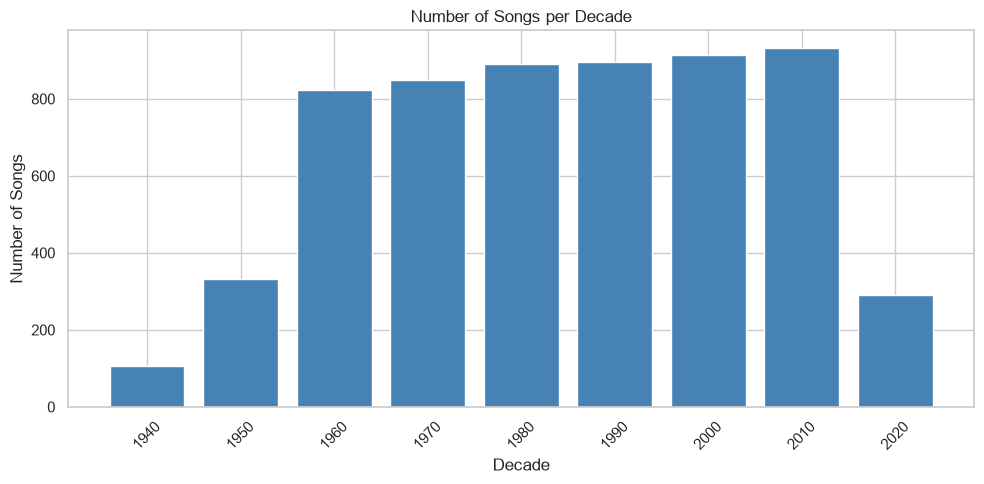

In [4]:
print(f"Number of songs: {df['song'].nunique()}")
print(f"Number of artists: {df['artist'].nunique()}")

songs_per_decade = df.groupby('decade').size().reset_index(name='number_of_songs')
print("\nSongs per decade (1946-2022):")
print(songs_per_decade)

plt.figure(figsize=(10, 5))
plt.bar(songs_per_decade['decade'].astype(str), songs_per_decade['number_of_songs'], color='steelblue')
plt.title('Number of Songs per Decade')
plt.xlabel('Decade')
plt.ylabel('Number of Songs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

> **Note:** The 2020s only contains ~290 songs (2020–2022), a partial decade
> compared to the ~800–930 songs in other decades. Keep this in mind when
> comparing that decade's percentages later — smaller samples are noisier.

## 3. Removing Stopwords

A raw word count is dominated by function words (the, a, to, you, i) that
carry no thematic meaning. To find genuinely meaningful "content" words, three
tiers of non-content words are filtered out:

1. **Grammar words** — pronouns, articles, prepositions (i, you, the, to, a...)
2. **Vocal filler / ad-libs** — non-lexical sounds common in songs (oh, yeah, na, la...)
3. **Conversational filler** — common but low-content words (like, know, just, got...)
4. **Contractions without apostrophes** — the tokenizer stripped apostrophes, so "don't"
   became the fake "word" `dont`, "I'll" became `ill`, etc. These are filtered separately
   so they aren't mistaken for real content words.

In [5]:
GRAMMAR_STOPWORDS = set("""
i you the a to and me it my in on that im your be of is with do
this was were are am he she they we our us his her their them
but not no so as at if or an
""".split())

FILLER_WORDS = set("oh yeah na la ooh uh ah mmm hey ha woah whoa".split())

CONVERSATIONAL_FILLER = set("""
like know just got get up down all for when what now can its
go want come will let too here there very more much never
gonna wanna gotta cause even still back one two
""".split())

CONTRACTIONS_NO_APOSTROPHE = set("""
dont cant wont youre theyre im ive youve theyve weve
whats thats aint isnt wasnt werent hasnt havent hadnt
wouldnt couldnt shouldnt didnt doesnt ill youll hell shell theyll
id youd hed shed wed theyd
""".split())

def remove_stopwords(tokens):
    return [w for w in tokens
            if w not in GRAMMAR_STOPWORDS
            and w not in FILLER_WORDS
            and w not in CONVERSATIONAL_FILLER
            and w not in CONTRACTIONS_NO_APOSTROPHE]

df['tokens_content'] = df['tokens'].apply(remove_stopwords)
print(df['tokens_content'].apply(len).describe())

count    6032.000000
mean      154.109748
std        87.770791
min         0.000000
25%        93.750000
50%       132.000000
75%       187.000000
max       756.000000
Name: tokens_content, dtype: float64


## 4. Collapsing Repeats Within a Song

A word repeated 50 times in one song's chorus shouldn't count the same as a
word that shows up once in 50 different songs — the second is a genuine
pattern across the dataset, the first is just one song's hook. Converting each
song's word list to a `set` collapses repeats **within a song** to a single
occurrence, so later counts measure **how many different songs** use a word
(song coverage), not raw repetition.

In [6]:
df['tokens_unique'] = df['tokens_content'].apply(lambda tokens: set(tokens))

print("With repeats:", len(df['tokens_content'].iloc[0]), "words")
print("Repeats collapsed:", len(df['tokens_unique'].iloc[0]), "words")

With repeats: 67 words
Repeats collapsed: 54 words


## 5. Most Common Words Overall (by Song Coverage)

Total songs: 6032

  love: appears in 3405 songs (56.4% of all songs)
  out: appears in 2461 songs (40.8% of all songs)
  see: appears in 2424 songs (40.2% of all songs)
  time: appears in 2381 songs (39.5% of all songs)
  baby: appears in 2351 songs (39.0% of all songs)
  say: appears in 2259 songs (37.5% of all songs)
  make: appears in 2123 songs (35.2% of all songs)
  way: appears in 2026 songs (33.6% of all songs)
  have: appears in 1980 songs (32.8% of all songs)
  take: appears in 1902 songs (31.5% of all songs)
  right: appears in 1866 songs (30.9% of all songs)
  how: appears in 1858 songs (30.8% of all songs)
  from: appears in 1817 songs (30.1% of all songs)
  tell: appears in 1719 songs (28.5% of all songs)
  feel: appears in 1647 songs (27.3% of all songs)
  need: appears in 1626 songs (27.0% of all songs)
  night: appears in 1568 songs (26.0% of all songs)
  girl: appears in 1517 songs (25.1% of all songs)
  could: appears in 1513 songs (25.1% of all songs)
  heart: appea

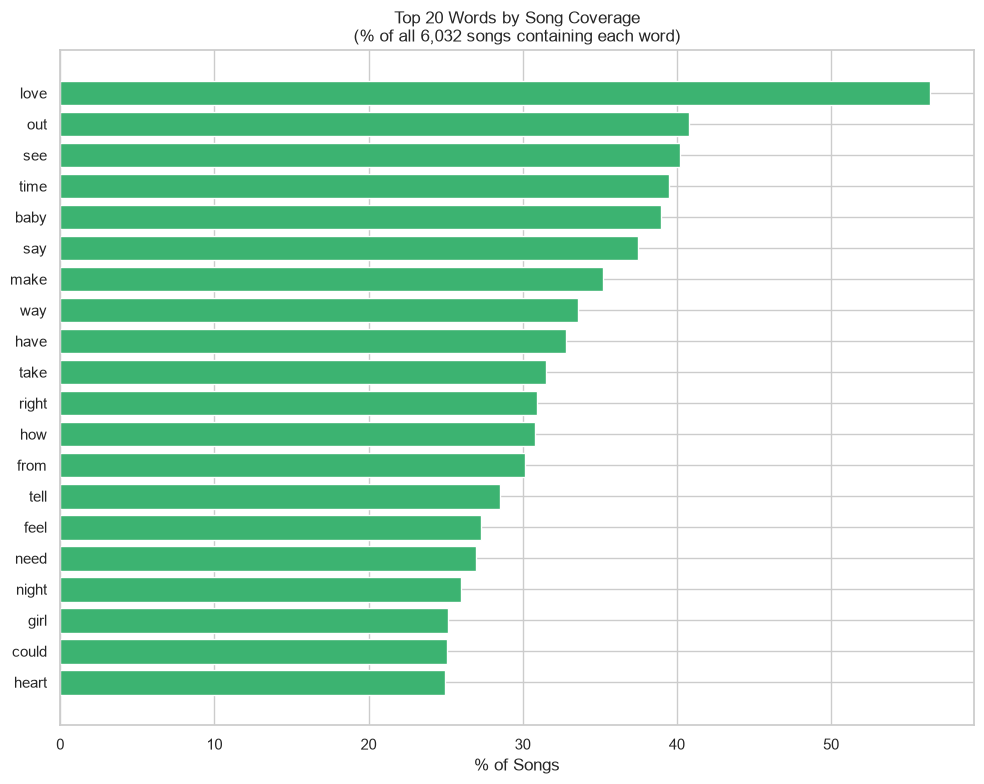

In [7]:
song_coverage = Counter()
for word_set in df['tokens_unique']:
    song_coverage.update(word_set)

print(f"Total songs: {len(df)}\n")
top_20 = song_coverage.most_common(20)
for word, count in top_20:
    pct = count / len(df) * 100
    print(f"  {word}: appears in {count} songs ({pct:.1f}% of all songs)")

words, counts = zip(*top_20)
pcts = [c / len(df) * 100 for c in counts]

plt.figure(figsize=(10, 8))
plt.barh(words, pcts, color='mediumseagreen')
plt.xlabel('% of Songs')
plt.title('Top 20 Words by Song Coverage\n(% of all 6,032 songs containing each word)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Headline stat:** "love" appears in **56.4%** of all 6,032 Billboard Hot 100
songs across 76 years — more than half of every hit song ever charted mentions love.

## 6. Top Words per Decade

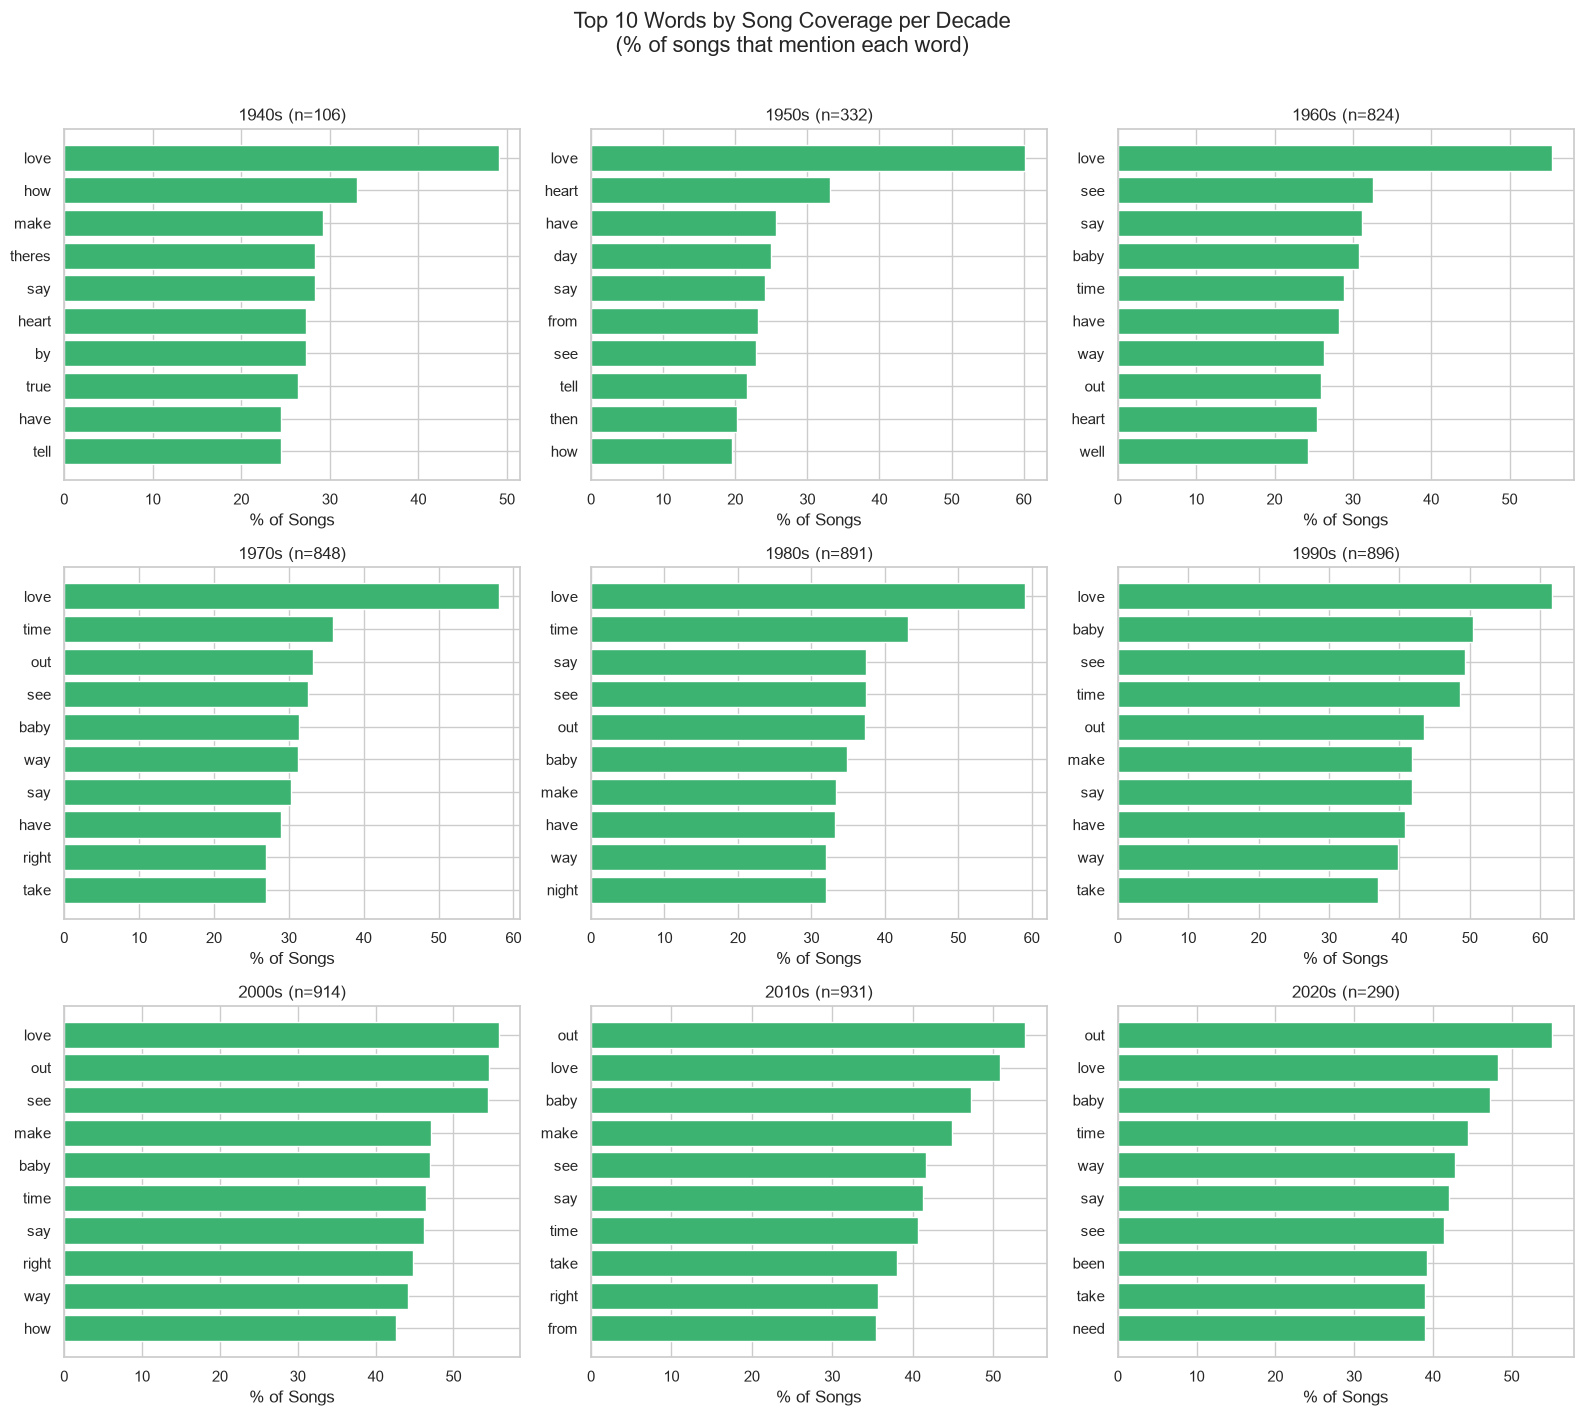

In [8]:
decades = sorted(df['decade'].unique())
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()

decade_coverage_top10 = {}

for i, decade in enumerate(decades):
    subset = df[df['decade'] == decade]
    n_songs = len(subset)
    coverage = Counter()
    for word_set in subset['tokens_unique']:
        coverage.update(word_set)

    top_10 = coverage.most_common(10)
    decade_coverage_top10[decade] = (top_10, n_songs)

    words = [w for w, c in top_10]
    pcts = [c / n_songs * 100 for w, c in top_10]

    axes[i].barh(words, pcts, color='mediumseagreen')
    axes[i].invert_yaxis()
    axes[i].set_title(f'{decade}s (n={n_songs})')
    axes[i].set_xlabel('% of Songs')

for j in range(len(decades), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Top 10 Words by Song Coverage per Decade\n(% of songs that mention each word)', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

"Love" is the #1 word by song coverage in every decade from the 1940s through
the 2000s. Starting in the 2010s, "out" overtakes it as the #1 word — the
first shift in 70 years.

## 7. Key Trend: Is "Love" Declining?

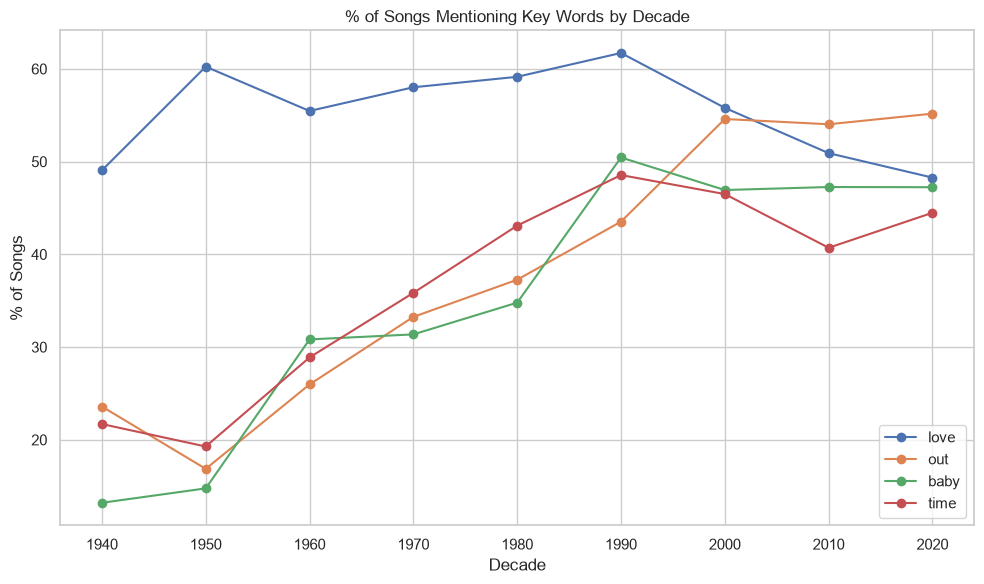

In [9]:
words_to_track = ['love', 'out', 'baby', 'time']
plt.figure(figsize=(10, 6))

for word in words_to_track:
    pct_by_decade = []
    for decade in decades:
        subset = df[df['decade'] == decade]
        n_songs = len(subset)
        count = sum(1 for word_set in subset['tokens_unique'] if word in word_set)
        pct_by_decade.append(count / n_songs * 100)
    plt.plot(decades, pct_by_decade, marker='o', label=word)

plt.title('% of Songs Mentioning Key Words by Decade')
plt.xlabel('Decade')
plt.ylabel('% of Songs')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Conclusions

- **"Love" is the most consistently used theme in Billboard history**, appearing
  in 56.4% of all songs from 1946–2022, and it was the clear #1 word in every
  decade from the 1940s through the 2000s.
- **"Love" mentions peaked around 1990 (~62% of songs)** and have declined
  fairly steadily since, dropping to roughly 48% by the 2020s — the lowest
  point in the dataset.
- **Other common words — "out," "baby," and "time" — were rare in the 1940s
  (10–25% of songs) but rose steadily across every decade**, converging with
  "love" by the 2010s–2020s.
- **The overall story isn't just "love declined" — it's that lyrical
  vocabulary diversified.** Mid-century hits leaned heavily on one dominant
  romantic theme; modern hits spread more evenly across a broader, more
  conversational vocabulary.

**Caveats:**
- The 2020s decade is incomplete (2020–2022 only, ~290 songs vs. 800–930 in
  other decades), so its percentages are noisier and less reliable than
  earlier, fully-sampled decades.
- Stopword filtering involves subjective judgment calls (e.g. whether to
  filter non-English words or slang); the thresholds used here favor keeping
  genuine vocabulary, including slang and foreign-language words, over
  aggressive filtering.
- This is a descriptive analysis (word frequency and trends), not a
  statistical test — differences between decades are visually notable but
  haven't been tested for statistical significance.